# Imports

In [1]:
!pip install -q --upgrade --force-reinstall "transformers==4.44.2" "accelerate==0.34.2" "tokenizers==0.19.1"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.7/43.7 kB 1.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 2.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 kB 1.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.7/41.7 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 109.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.4/324.4 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 110.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 36.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 94.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.2/100.2 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 47.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 801.8/801.8 kB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import random
import torch
import re
 
print("Libraries loaded ")

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Libraries loaded 
/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


# Cuda check and Wandb Setup

**Cuda setup**

In [3]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Device: {device}")

Device: cuda


**WANDB Setup**

In [4]:
import wandb
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
PROJECT_NAME = "DL-GenAi-2026-T2"
ENTITY_NAME = "23f2001548-dl-genai-project"
os.environ["WANDB_PROJECT"] = PROJECT_NAME
os.environ["WANDB_ENTITY"] = ENTITY_NAME
wandb_key = user_secrets.get_secret("WANDB_API_KEY")
wandb.login(key=wandb_key)

print("W&B login successful")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


W&B login successful


# Map@3 Metric function

In [5]:
def map_at_3(y_true, y_pred_ranked):
    scores = []
    for true, preds in zip(y_true, y_pred_ranked):
        score = 0.0
        for i, p in enumerate(preds[:3]):
            if p == true:
                score = 1.0 / (i + 1)
                break
        scores.append(score)
    return np.mean(scores)

# Loading datasets

In [6]:
BASE = '/kaggle/input/competitions/smart-mcq-solver-challenge'
 
train = pd.read_csv(f'{BASE}/train.csv')
test = pd.read_csv(f'{BASE}/test.csv')
sub = pd.read_csv(f'{BASE}/sample_submission.csv')
 
OPTIONS = list('ABCDE')
 
print(f"Train : {train.shape}")
print(f"Test : {test.shape}")
print(f"Sub : {sub.shape}")

Train : (2000, 8)
Test : (500, 7)
Sub : (500, 2)


# EDA

In [7]:
# Datatypes of collumns of all datasets
print("=== TRAIN COLUMNS ===")
print(train.dtypes)
print("\n=== TEST COLUMNS ===")
print(test.dtypes)
print("\n=== SAMPLE SUBMISSION ===")
print(sub.head())

=== TRAIN COLUMNS ===
id         int64
prompt    object
A         object
B         object
C         object
D         object
E         object
answer    object
dtype: object

=== TEST COLUMNS ===
id         int64
prompt    object
A         object
B         object
C         object
D         object
E         object
dtype: object

=== SAMPLE SUBMISSION ===
   ID Prediction
0   1      A B C
1   2      A B C
2   3      A B C
3   4      A B C
4   5      A B C


Since all columns are object type(text) and there is no numerical data this is purely a text/NLP problem.

In [8]:
# First look of data
print("=== TRAIN HEAD ===")
display(train.head(3))
print("\n=== TEST HEAD ===")
display(test.head(3))

=== TRAIN HEAD ===


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C



=== TEST HEAD ===


,id,prompt,A,B,C,D,E
0,1,Pick the best possible answer: What is the rel...,"For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p...","For every eigenstate of one Hamiltonian, its p..."
1,2,"What is the estimated redshift of CEERS-93316,...","Approximately z = 6.0, corresponding to 1 bill...","Approximately z = 16.7, corresponding to 235.8...","Approximately z = 3.0, corresponding to 5 bill...","Approximately z = 10.0, corresponding to 13 bi...","Approximately z = 13.0, corresponding to 30 bi..."
2,3,Pick the best possible answer: What is the rea...,The sun appears yellowish due to a reflection ...,"The longer wavelengths of light, such as red a...",The sun appears yellowish due to the scatterin...,The sun emits a yellow light due to its own sp...,The atmosphere absorbs the shorter wavelengths...


As we can see the options are tricky and very similar.The main challenge is observing differences between options and not just knowing the topic broadly due to the similarity between options.

In [9]:
# Specific Row look
row = train.iloc[7]
print("PROMPT:", row['prompt'])
for opt in OPTIONS:
    print(f"[{opt}]", row[opt])
print("\nCORRECT ANSWER:", row['answer'])

PROMPT: Select the most accurate option: What is the Liouville density? among the listed options.
[A] The Liouville density is a probability distribution that specifies the probability of finding a particle at a certain position in phase space for a collection of particles.
[B] The Liouville density is a quasiprobability distribution that plays an analogous role to the probability distribution for a quantum particle.
[C] The Liouville density is a bounded probability distribution that is a convenient indicator of quantum-mechanical interference.
[D] The Liouville density is a probability distribution that takes on negative values for states which have no classical model.
[E] The Liouville density is a probability distribution that satisfies all the properties of a conventional probability distribution for a quantum particle.

CORRECT ANSWER: A


Just as we had seen in the previous first look of data here we can see that the model needs to know the precise definitions and not just similar type of concepts beacuse the dataset is delibirately putting related but wrong concepts as distractors.

In [10]:
#Missing values
print("=== TRAIN — NULL VALUES ===")
print(train.isnull().sum())
print("\n=== TEST — NULL VALUES ===")
print(test.isnull().sum())
# Duplicate check
print(f"Duplicate prompts in train : {train['prompt'].duplicated().sum()}")
print(f"Duplicate prompts in test  : {test['prompt'].duplicated().sum()}")

=== TRAIN — NULL VALUES ===
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

=== TEST — NULL VALUES ===
id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
dtype: int64
Duplicate prompts in train : 242
Duplicate prompts in test  : 8


There are absolutely no missing data anywhere so no need to do null handling or imputation but the duplicate prompts in train will confuse and damage our models performance if same prompt gives different answers so lets check that.

In [11]:
# Checking if duplicate prompts have same or different answers
dup = train[train.duplicated(subset='prompt', keep=False)]
print(dup[['prompt', 'answer']].sort_values('prompt'))

conflict = dup.groupby('prompt')['answer'].nunique()
print("\nPrompts with conflicting answers:", (conflict > 1).sum())

                                                 prompt answer
605   Choose the correct answer: What are permutatio...      E
456   Choose the correct answer: What are permutatio...      E
439   Choose the correct answer: What are permutatio...      E
1464  Choose the correct answer: What are permutatio...      E
42    Choose the correct answer: What are permutatio...      E
...                                                 ...    ...
1313  Which of the following is correct? Which of th...      D
1649  Which of the following is correct? Who propose...      B
708   Which of the following is correct? Who propose...      B
1623  Which of the following is correct? Who was Gio...      D
654   Which of the following is correct? Who was Gio...      D

[454 rows x 2 columns]

Prompts with conflicting answers: 0


Since we have same duplicates it wont have that much effect on model training but still the model will give more importance to the duplicated prompts creating bias towards repesated questions so we will just drop them.

In [12]:
train = train.drop_duplicates(subset='prompt', keep='first').reset_index(drop=True)
print("Train size after removing duplicates:", len(train))

Train size after removing duplicates: 1758


=== ANSWER DISTRIBUTION ===
answer
A    326
B    430
C    401
D    314
E    287
Name: count, dtype: int64


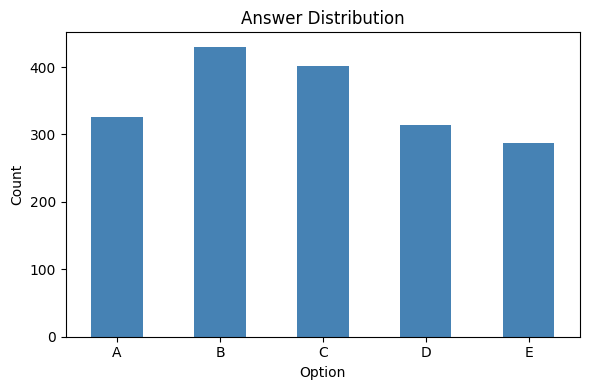

In [13]:
# Answer Distribution visualization
ans_counts = train['answer'].value_counts().sort_index()
print("=== ANSWER DISTRIBUTION ===")
print(ans_counts)

# Barchart demonstration for distributiuon
ans_counts.plot(kind='bar', color='steelblue', figsize=(6,4))
plt.title('Answer Distribution')
plt.xlabel('Option')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

B is most common (430) and E is least common (287) hence data is slightly imbalanced but our models won't be heavily biased toward predicting one letter over others as none of the option is dominant or rare.

=== PROMPT LENGTH ===
count    1758.0
mean      117.2
std        45.0
min        19.0
25%        87.0
50%       111.0
75%       141.0
max       337.0
Name: prompt, dtype: float64

=== AVERAGE OPTION LENGTH ===
  Option A: 163.3 chars
  Option B: 165.7 chars
  Option C: 166.6 chars
  Option D: 162.2 chars
  Option E: 163.4 chars


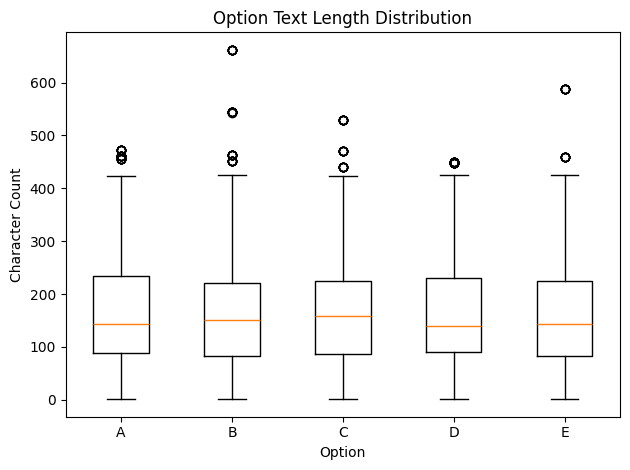

In [14]:
# Text length visualization
print("=== PROMPT LENGTH ===")
print(train['prompt'].str.len().describe().round(1))
print("\n=== AVERAGE OPTION LENGTH ===")
for opt in OPTIONS:
    avg = train[opt].str.len().mean()
    print(f"  Option {opt}: {avg:.1f} chars")

# Box plot of option lengths
length_data = [train[opt].str.len().values for opt in OPTIONS]
plt.boxplot(length_data, labels=OPTIONS)
plt.title('Option Text Length Distribution')
plt.xlabel('Option')
plt.ylabel('Character Count')
plt.tight_layout()
plt.show()

Similar character counts across all options so no conclusion with this.

=== AVERAGE WORD COUNT PER OPTION ===
 Option A: 26.0 words
 Option B: 26.3 words
 Option C: 26.4 words
 Option D: 25.9 words
 Option E: 26.1 words


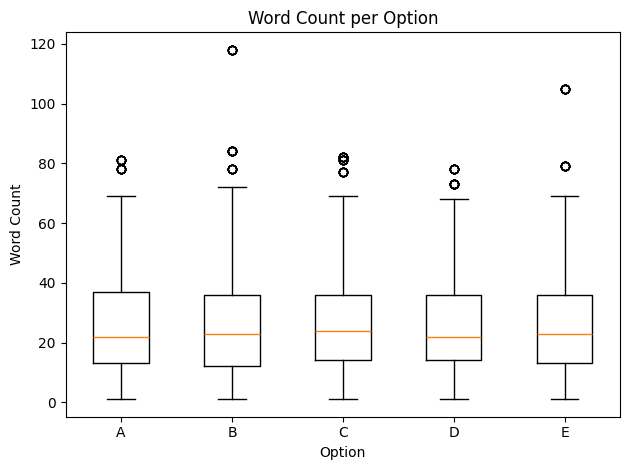

In [15]:
print("=== AVERAGE WORD COUNT PER OPTION ===")
for opt in OPTIONS:
    avg = train[opt].str.split().str.len().mean()
    print(f" Option {opt}: {avg:.1f} words")

word_data = [train[opt].str.split().str.len().values for opt in OPTIONS]
plt.boxplot(word_data, labels=OPTIONS)
plt.title('Word Count per Option')
plt.xlabel('Option')
plt.ylabel('Word Count')
plt.tight_layout()
plt.show()

All options average is almost identical except few outliers like B has one option near to 118 words and E has one option around 105 words but that wont have any effect.

=== WORD OVERLAP(prompt → correct answer) ===
count    1758.00
mean        5.04
std         3.41
min         0.00
25%         3.00
50%         5.00
75%         7.00
max        18.00
Name: overlap_correct, dtype: float64


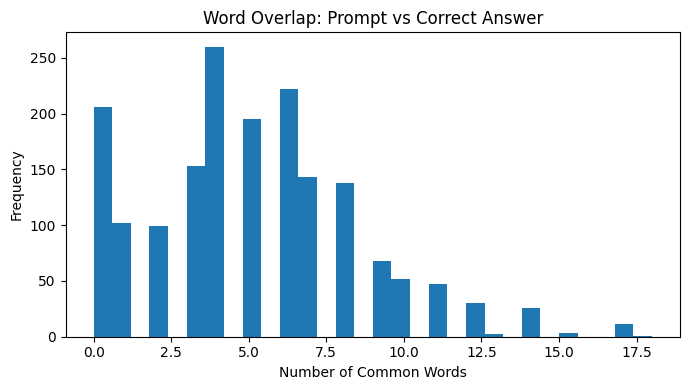

In [16]:
# Word overlap in prompt and correct answer
def word_overlap(prompt, answer_text):
    prompt_words  = set(re.findall(r'\w+', prompt.lower()))
    answer_words  = set(re.findall(r'\w+', answer_text.lower()))
    common = prompt_words & answer_words
    return len(common)

train['correct_option_text'] = train.apply(lambda r: r[r['answer']], axis=1)
train['overlap_correct'] = train.apply(lambda r: word_overlap(r['prompt'], r['correct_option_text']), axis=1)

print("=== WORD OVERLAP(prompt → correct answer) ===")
print(train['overlap_correct'].describe().round(2))

train['overlap_correct'].plot(kind='hist', bins=30, figsize=(7,4))
plt.title('Word Overlap: Prompt vs Correct Answer')
plt.xlabel('Number of Common Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

Average overlap is 5 words, so correct answers typically share 5 words with the question  and aroound 205 questions have 0 word overlap hence Word overlap is too low and unreliable to be useful as a feature.

Correct option avg word count : 28.5
Wrong option avg word count: 25.6


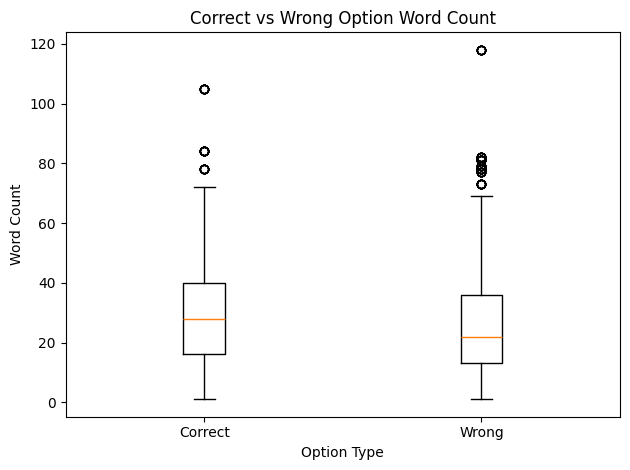

In [17]:
# Correct vs wrong option's word count comparision
correct_lengths = []
wrong_lengths = []

for _, row in train.iterrows():
    for opt in OPTIONS:
        length = len(row[opt].split())
        if opt == row['answer']:
            correct_lengths.append(length)
        else:
            wrong_lengths.append(length)

print(f"Correct option avg word count : {np.mean(correct_lengths):.1f}")
print(f"Wrong option avg word count: {np.mean(wrong_lengths):.1f}")

plt.boxplot([correct_lengths, wrong_lengths], labels=['Correct', 'Wrong'])
plt.title('Correct vs Wrong Option Word Count')
plt.xlabel('Option Type')
plt.ylabel('Word Count')
plt.tight_layout()
plt.show()

Small but real pattern, correct answers are slightly longer with around ~3 words difference hence there is a tiny length bias in dataset.

=== QUESTION TYPE COUNTS ===
question_type
Other                 513
Pick the best         277
Select                273
Which                 260
Determine             257
What is / What are    169
Who                     7
How                     2
Name: count, dtype: int64


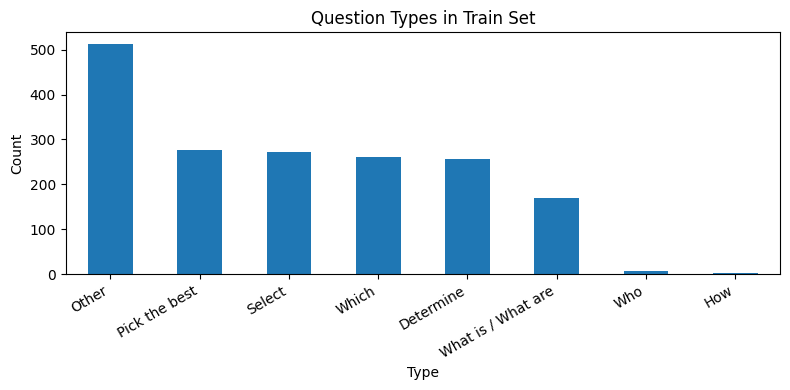

In [18]:
patterns = {
    'What is / What are' : r'^what (is|are)',
    'Which': r'^which',
    'Pick the best': r'^pick',
    'Select': r'^select',
    'Determine': r'^determine',
    'How': r'^how',
    'Why': r'^why',
    'Who': r'^who',
    'When': r'^when',
    'Other': None
}

def get_question_type(prompt):
    p = prompt.lower().strip()
    for label, pattern in patterns.items():
        if pattern and re.match(pattern, p):
            return label
    return 'Other'

train['question_type'] = train['prompt'].apply(get_question_type)
print("=== QUESTION TYPE COUNTS ===")
print(train['question_type'].value_counts())

train['question_type'].value_counts().plot(kind='bar', figsize=(8,4))
plt.title('Question Types in Train Set')
plt.xlabel('Type')
plt.ylabel('Count')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

Dataset is dominated by Other (513) and choice-based questions (Pick the best, Select, Which, Determine — ~257-277 each), with definition-based What is/What are (169) also present, while Who and How are nearly absent (7 and 2) — meaning the model must handle varied question formats with no single type to over-optimize for.

# Train Val Split

In [19]:
train_df, val_df = [df.reset_index(drop=True) for df in train_test_split(train, test_size=0.15, random_state=SEED, stratify=train['answer'])]
print(f"Train:{len(train_df)} | Val:{len(val_df)}")

Train:1494 | Val:264


# MODEL 1-: Tf Idf + Logistic Regression


In [20]:
# # Cleaning text
# def clean_text(text):
#     text = str(text).lower()
#     text = re.sub(r'[^a-z0-9\s]', '', text)
#     text = re.sub(r'\s+', ' ', text).strip()
#     return text

# for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
#     train_df[f'{col}_clean'] = train_df[col].apply(clean_text)
#     val_df[f'{col}_clean'] = val_df[col].apply(clean_text)
#     test[f'{col}_clean'] = test[col].apply(clean_text)
# print("Cleaning done")

# # Combining prompt and options
# texts, labels = [], []
# for _, row in train_df.iterrows():
#     for opt in OPTIONS:
#         texts.append(row['prompt_clean'] + ' [SEP] ' + row[f'{opt}_clean'])
#         labels.append(1 if row['answer'] == opt else 0)

# tfidf   = TfidfVectorizer(ngram_range=(1, 2), max_features=50000, min_df=2, max_df=0.9)
# X_train = tfidf.fit_transform(texts)

# lr = LogisticRegression(max_iter=1000, random_state=SEED, class_weight='balanced')
# lr.fit(X_train, labels)
# print("Training done")

# # Prediction and WandB log
# def get_predictions(df):
#     all_preds = []
#     for _, row in df.iterrows():
#         scores = []
#         for opt in OPTIONS:
#             vec  = tfidf.transform([row['prompt_clean'] + ' ' + row[f'{opt}_clean']])
#             prob = lr.predict_proba(vec)[0][1]
#             scores.append(prob)
#         ranked = np.argsort(scores)[::-1]
#         all_preds.append([OPTIONS[i] for i in ranked])
#     return all_preds

# val_preds = get_predictions(val_df)
# val_top1 = [preds[0] for preds in val_preds]
# true_labels = val_df['answer'].tolist()

# map3 = map_at_3(true_labels, val_preds)
# acc = accuracy_score(true_labels, val_top1)
# f1 = f1_score(true_labels, val_top1, average='macro')

# print(f"Val mAP@3 : {map3:.4f}")
# print(f"Val Accuracy : {acc:.4f}")  
# print(f"Val F1 (macro) : {f1:.4f}") 

# run = wandb.init(entity="23f2001548-dl-genai-project",
#                  project="DL-GenAi-2026-T2", name='tfidf-lr-v3',
#                  config={'model': 'tfidf_lr', 'ngram': '(1,2)',
#                          'max_features': 50000,'min_df': 2,
#                          'max_df': 0.9, 'metrics': 'map3, accuracy, f1' })
# wandb.log({'val_map3': map3, 'val_accuracy': acc, 'val_f1_macro' : f1})
# wandb.finish()

# MODEL 2 Pretrained DeBERTa-V3 

In [21]:
# from transformers import AutoTokenizer, AutoModelForMultipleChoice, TrainingArguments, Trainer
# from torch.utils.data import Dataset

# MODEL_NAME = "microsoft/deberta-v3-base"  
# MAX_LEN = 256                           
# label2idx = {opt: i for i, opt in enumerate(OPTIONS)}
# idx2label = {i: opt for opt, i in label2idx.items()}   

# tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
# model = AutoModelForMultipleChoice.from_pretrained(MODEL_NAME).to(device)
# print(f" Loaded {MODEL_NAME}")

# # MCQDataset 

# class MCQDataset(Dataset):
#     def __init__(self, df, tokenizer, is_train=True):
#         self.df = df.reset_index(drop=True)
#         self.tokenizer = tokenizer
#         self.is_train = is_train

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         row = self.df.iloc[idx]
#         options = [row[opt] for opt in OPTIONS]
#         encoded = self.tokenizer(
#             [row['prompt']] * 5, options,
#             truncation=True,
#             max_length=MAX_LEN,
#             padding='max_length'
#         )
#         item = {
#             'input_ids': torch.tensor(encoded['input_ids']),
#             'attention_mask': torch.tensor(encoded['attention_mask'])
#         }
#         if self.is_train:
#             item['labels'] = torch.tensor(label2idx[row['answer']])
#         return item

# train_dataset = MCQDataset(train_df, tokenizer)
# val_dataset= MCQDataset(val_df, tokenizer)
# test_dataset = MCQDataset(test, tokenizer, is_train=False)
# print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")

# def compute_metrics(eval_pred):
#     logits, labels = eval_pred
#     probs = torch.softmax(torch.tensor(logits), dim=1).numpy()
#     preds = np.argmax(logits, axis=1)

#     acc = accuracy_score(labels, preds)
#     f1 = f1_score(labels, preds, average='macro')

#     top3 = np.argsort(-probs, axis=1)[:, :3]
#     true_labels = [idx2label[i] for i in labels]
#     pred_ranked = [[idx2label[i] for i in row] for row in top3]

#     map3 = map_at_3(true_labels, pred_ranked)

#     return {'accuracy': acc, 'f1_macro': f1, 'map_at_3': map3}

# # Training

# training_args = TrainingArguments(
#     output_dir = './deberta_mcq',
#     run_name = 'deberta-v3-mcq-v6',   
#     report_to = 'wandb',
#     learning_rate = 1e-5,                
#     per_device_train_batch_size = 4,
#     per_device_eval_batch_size = 8,
#     gradient_accumulation_steps = 4,        
#     num_train_epochs = 7,                    
#     weight_decay = 0.01, warmup_ratio = 0.1,                           
#     max_grad_norm = 1.0,                  
#     eval_strategy= 'epoch',
#     save_strategy= 'epoch',
#     fp16 = False,
#     logging_steps = 20,
#     save_total_limit = 1,
#     load_best_model_at_end = True,
#     metric_for_best_model = 'map_at_3',
#     greater_is_better = True,
#     seed = SEED
# )

# trainer = Trainer(
#     model = model, args = training_args,
#     train_dataset = train_dataset,
#     eval_dataset = val_dataset,
#     compute_metrics = compute_metrics
# )

# trainer.train()
# print("Training done")
# print(trainer.evaluate())

# predictions = trainer.predict(test_dataset)
# probs = torch.softmax(torch.tensor(predictions.predictions), dim=1).numpy()
# top3_idx = np.argsort(-probs, axis=1)[:, :3]

# sub['Prediction'] = [' '.join([idx2label[i] for i in row]) for row in top3_idx]
# sub.to_csv('submission.csv', index=False)
# print("Submission saved")
# print(sub.head())

# Model-3 BiLSTM from scratch

In [22]:
from collections import Counter
from torch.utils.data import DataLoader
import torch.nn as nn
from torch.utils.data import Dataset
label2idx = {opt: i for i, opt in enumerate(OPTIONS)}
idx2label = {i: opt for opt, i in label2idx.items()}

In [23]:
# BiLSTM From Scratch

# Vocabulary
def tokenize(text):
    return str(text).lower().split()

counter = Counter()
for col in ['prompt'] + OPTIONS:
    for text in train_df[col]:
        counter.update(tokenize(text))

vocab = {'<PAD>': 0, '<UNK>': 1}
for word, freq in counter.items():
    if freq >= 2:
        vocab[word] = len(vocab)

VOCAB_SIZE = len(vocab)
print(f"Vocabulary size: {VOCAB_SIZE}")

def text_to_ids(text, max_len=128):
    tokens = tokenize(text)[:max_len]
    ids = [vocab.get(t, 1) for t in tokens]
    ids += [0] * (max_len - len(ids))
    return ids

# Dataset
class BiLSTMDataset(Dataset):
    def __init__(self, df, is_train=True):
        self.df = df.reset_index(drop=True)
        self.is_train = is_train

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        item = {
            'prompt' : torch.tensor(text_to_ids(row['prompt']), dtype=torch.long),
            'options': torch.tensor([text_to_ids(row[opt]) for opt in OPTIONS], dtype=torch.long)
        }
        if self.is_train:
            item['label'] = torch.tensor(label2idx[row['answer']], dtype=torch.long)
        return item

train_bilstm = BiLSTMDataset(train_df)
val_bilstm = BiLSTMDataset(val_df)
test_bilstm = BiLSTMDataset(test, is_train=False)

train_loader = DataLoader(train_bilstm, batch_size=32, shuffle=True)
val_loader = DataLoader(val_bilstm,   batch_size=64, shuffle=False)
test_loader = DataLoader(test_bilstm,  batch_size=64, shuffle=False)

print(f"Train -: {len(train_bilstm)} | Val -: {len(val_bilstm)}")

# Model
class BiLSTMEncoder(nn.Module):
    def __init__(self, vocab_size, embed_dim=128, hidden_dim=256):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True, bidirectional=True)
        self.dropout = nn.Dropout(0.5)

    def forward(self, x):
        emb = self.dropout(self.embedding(x))
        out, _ = self.lstm(emb)
        return out.mean(dim=1)

class BiLSTMMCQ(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.encoder = BiLSTMEncoder(vocab_size)
        self.classifier = nn.Linear(256 * 2 * 2, 1)

    def forward(self, prompt, options):
        prompt_enc = self.encoder(prompt)
        scores = []
        for i in range(5):
            opt_enc = self.encoder(options[:, i, :])
            combined = torch.cat([prompt_enc, opt_enc], dim=1)
            scores.append(self.classifier(combined))
        return torch.cat(scores, dim=1)

model_bilstm = BiLSTMMCQ(VOCAB_SIZE).to(device)
print(f"Parameters: {sum(p.numel() for p in model_bilstm.parameters()):,}")

# Training
optimizer = torch.optim.Adam(model_bilstm.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

run = wandb.init(
    project = PROJECT_NAME,
    entity = ENTITY_NAME,
    name = 'bilstm-scratch-v5',
    config = {'model': 'bilstm', 'embed_dim': 128,'hidden_dim': 256, 'epochs': 10, 'max_len': 128, 'dropout':0.5})

best_map3 = 0

for epoch in range(10):
    model_bilstm.train()
    total_loss = 0
    for batch in train_loader:
        prompt = batch['prompt'].to(device)
        options = batch['options'].to(device)
        labels = batch['label'].to(device)
        optimizer.zero_grad()
        loss = criterion(model_bilstm(prompt, options), labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_bilstm.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()

    model_bilstm.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in val_loader:
            prompt = batch['prompt'].to(device)
            options = batch['options'].to(device)
            probs = torch.softmax(model_bilstm(prompt, options), dim=1).cpu().numpy()
            top3 = np.argsort(-probs, axis=1)[:, :3]
            all_preds.extend([[idx2label[i] for i in row] for row in top3])
            all_labels.extend([idx2label[l.item()] for l in batch['label']])

    top1 = [p[0] for p in all_preds]
    map3 = map_at_3(all_labels, all_preds)
    if map3 > best_map3:
        best_map3 = map3
        torch.save(model_bilstm.state_dict(), 'bilstm_best.pth')
    acc = accuracy_score(all_labels, top1)
    f1 = f1_score(all_labels, top1, average='macro')

    print(f"Epoch {epoch+1}/10 | Loss: {total_loss/len(train_loader):.4f} | mAP@3: {map3:.4f} | Acc: {acc:.4f} | F1: {f1:.4f}")
    wandb.log({'epoch': epoch + 1, 'train_loss': total_loss/len(train_loader),
               'val_map3': map3, 'val_accuracy': acc, 'val_f1_macro': f1})

wandb.finish()

# Preds
model_bilstm.load_state_dict(torch.load('bilstm_best.pth'))   
print(f" Loaded best model | mAP@3: {best_map3:.4f}") 
model_bilstm.eval()
all_test_preds = []
with torch.no_grad():
    for batch in test_loader:
        prompt = batch['prompt'].to(device)
        options = batch['options'].to(device)
        probs = torch.softmax(model_bilstm(prompt, options), dim=1).cpu().numpy()
        top3 = np.argsort(-probs, axis=1)[:, :3]
        all_test_preds.extend([[idx2label[i] for i in row] for row in top3])

Vocabulary size: 3804
Train -: 1494 | Val -: 264
Parameters: 1,278,465


wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260802_061057-vaj5q3kt
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run bilstm-scratch-v5
wandb: ⭐️ View project at https://wandb.ai/23f2001548-dl-genai-project/DL-GenAi-2026-T2
wandb: 🚀 View run at https://wandb.ai/23f2001548-dl-genai-project/DL-GenAi-2026-T2/runs/vaj5q3kt


Epoch 1/10 | Loss: 1.4831 | mAP@3: 0.6136 | Acc: 0.4242 | F1: 0.4235
Epoch 2/10 | Loss: 1.2247 | mAP@3: 0.7178 | Acc: 0.6061 | F1: 0.6019
Epoch 3/10 | Loss: 1.0512 | mAP@3: 0.8895 | Acc: 0.8295 | F1: 0.8272
Epoch 4/10 | Loss: 0.8984 | mAP@3: 0.9072 | Acc: 0.8371 | F1: 0.8330
Epoch 5/10 | Loss: 0.9801 | mAP@3: 0.9438 | Acc: 0.9053 | F1: 0.9024
Epoch 6/10 | Loss: 0.8237 | mAP@3: 0.9350 | Acc: 0.8902 | F1: 0.8860
Epoch 7/10 | Loss: 0.7633 | mAP@3: 0.9634 | Acc: 0.9280 | F1: 0.9248
Epoch 8/10 | Loss: 0.6782 | mAP@3: 0.9527 | Acc: 0.9167 | F1: 0.9167
Epoch 9/10 | Loss: 0.6374 | mAP@3: 0.9798 | Acc: 0.9621 | F1: 0.9608


wandb: updating run metadata


Epoch 10/10 | Loss: 0.6172 | mAP@3: 0.9741 | Acc: 0.9508 | F1: 0.9494


wandb: uploading data
wandb: 
wandb: Run history:
wandb:        epoch ▁▂▃▃▄▅▆▆▇█
wandb:   train_loss █▆▅▃▄▃▂▁▁▁
wandb: val_accuracy ▁▃▆▆▇▇█▇██
wandb: val_f1_macro ▁▃▆▆▇▇█▇██
wandb:     val_map3 ▁▃▆▇▇▇█▇██
wandb: 
wandb: Run summary:
wandb:        epoch 10
wandb:   train_loss 0.61719
wandb: val_accuracy 0.95076
wandb: val_f1_macro 0.94937
wandb:     val_map3 0.97412
wandb: 
wandb: 🚀 View run bilstm-scratch-v5 at: https://wandb.ai/23f2001548-dl-genai-project/DL-GenAi-2026-T2/runs/vaj5q3kt
wandb: ⭐️ View project at: https://wandb.ai/23f2001548-dl-genai-project/DL-GenAi-2026-T2
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260802_061057-vaj5q3kt/logs


 Loaded best model | mAP@3: 0.9798


# Prediction Submission

In [24]:
sub['Prediction'] = [' '.join(p[:3]) for p in all_test_preds]
sub.to_csv('submission.csv', index=False)
print("Submission saved")
print(sub.head())

Submission saved
   ID Prediction
0   1      A E D
1   2      B A D
2   3      B E D
3   4      E C D
4   5      C A D
